
## Job Prospects in Technology and AI

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap
from sklearn.metrics import classification_report, roc_auc_score, mean_absolute_error, mean_squared_error, r2_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler


In [3]:

# load dataset- in same directory
jobs = pd.read_csv('global_ai_jobs.csv')

# general overview of data; check for missing data
print("Shape:", jobs.shape)
print("\nColumns and Types:\n", jobs.dtypes)
print("\nMissing Values:\n", jobs.isnull().sum())
print("\nHead:\n", jobs.head(3))

Shape: (90000, 35)

Columns and Types:
 id                           int64
country                        str
job_role                       str
ai_specialization              str
experience_level               str
experience_years             int64
salary_usd                   int64
bonus_usd                    int64
education_required             str
industry                       str
company_size                   str
interview_rounds             int64
year                         int64
work_mode                      str
weekly_hours               float64
company_rating             float64
job_openings                 int64
hiring_difficulty_score    float64
layoff_risk                float64
ai_adoption_score            int64
company_funding_billion    float64
economic_index             float64
ai_maturity_years            int64
offer_acceptance_rate      float64
tax_rate_percent           float64
vacation_days                int64
skill_demand_score           int64
automation_risk

In [3]:
# check key summary statistics and unique values for key categorical features
key_numerics = ['salary_usd', 'skill_demand_score', 'experience_years', 'job_openings', 'ai_adoption_score']
print("Key Numeric Summary:\n", jobs[key_numerics].describe())

print("\nEducation Required Distributions:")
print(jobs['education_required'].value_counts(normalize=True) * 100)

print("\nTop Job Roles:")
print(jobs['job_role'].value_counts().head(10))

print("\nTop AI Specializations:")
print(jobs['ai_specialization'].value_counts().head(10))

print("\nTop Hiring Industries:")
print(jobs['industry'].value_counts().head(10))

print("\nYear Range:", jobs['year'].min(), "to", jobs['year'].max())

Key Numeric Summary:
           salary_usd  skill_demand_score  experience_years  job_openings  \
count   90000.000000        90000.000000      90000.000000  90000.000000   
mean    96546.249222           50.461200          7.028133     17.521867   
std     43935.479553           28.853798          5.889327      7.848576   
min     28000.000000            1.000000          0.000000      1.000000   
25%     64676.750000           25.000000          2.000000     12.000000   
50%     87544.000000           51.000000          6.000000     17.000000   
75%    123906.000000           75.000000         12.000000     23.000000   
max    300622.000000          100.000000         19.000000     50.000000   

       ai_adoption_score  
count       90000.000000  
mean           71.375167  
std            13.767769  
min             1.000000  
25%            62.000000  
50%            71.000000  
75%            81.000000  
max           100.000000  

Education Required Distributions:
education_requi

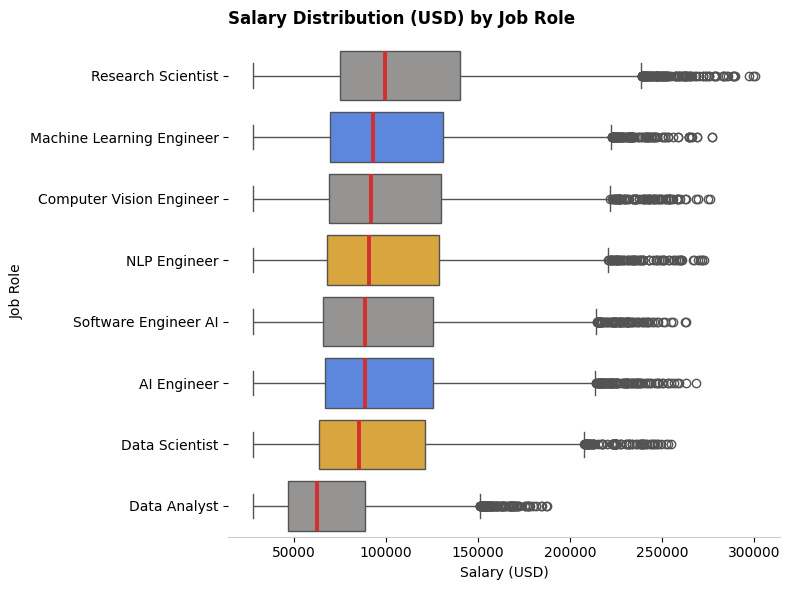

In [4]:

# color palette setup
COLOR_TOP = "#4680F2"
COLOR_MID = "#969393"
COLOR_LOW = "#F2AD24"
RED_MEDIAN = "#D32F2F"

# order job roles by median salary
role_order = (
    jobs.groupby("job_role")["salary_usd"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)
role_colors = [
    COLOR_TOP
    if i < 2
    else COLOR_LOW
    if i >= len(role_order) - 2
    else COLOR_MID
    for i in range(len(role_order))
]

fig, ax = plt.subplots(figsize=(8, 6))

# clean spines
ax.spines["left"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#cccccc")

# boxplot with red median line
medianprops = dict(linestyle="-", linewidth=2.8, color=RED_MEDIAN)
sns.boxplot(
    ax=ax,
    data=jobs,
    x="salary_usd",
    y="job_role",
    hue="job_role",
    order=role_order,
    palette=role_colors,
    medianprops=medianprops,
    showmeans=False,
)

if ax.get_legend():
    ax.get_legend().remove()

ax.set_xlabel("Salary (USD)")
ax.set_ylabel("Job Role")
ax.set_title(
    "Salary Distribution (USD) by Job Role",
    fontsize=12,
    fontweight="bold",
    loc="left",
    pad=15,
)

plt.tight_layout()
plt.show()

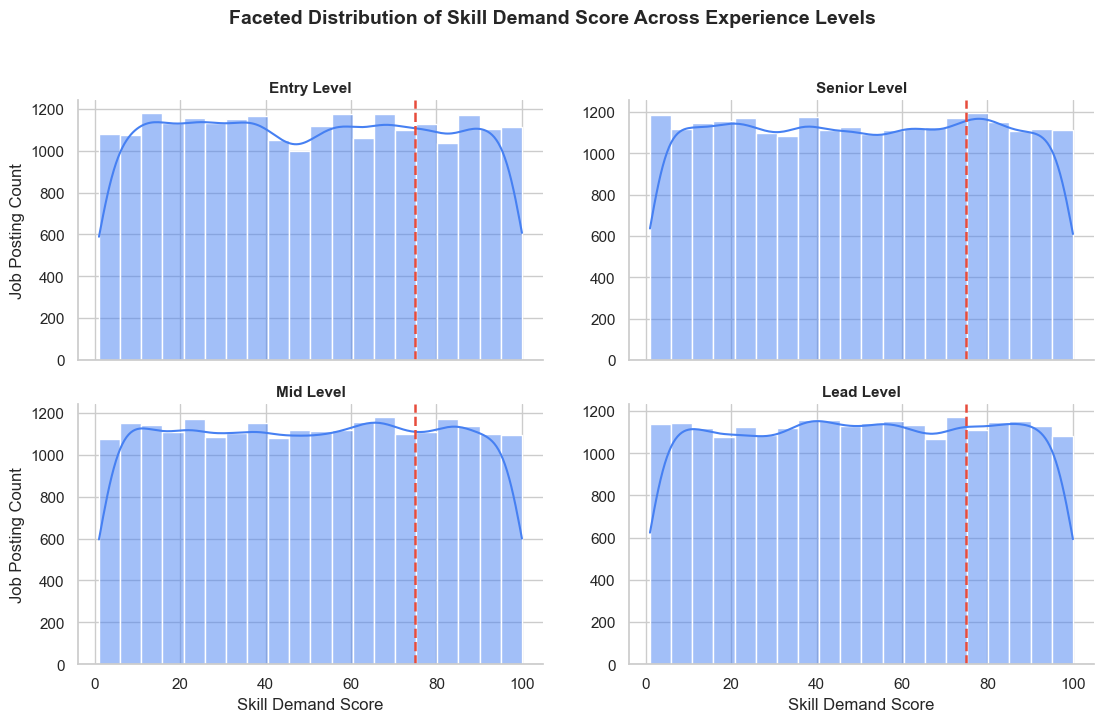

In [5]:

# set visual style
sns.set_theme(style="whitegrid")

# define palette colors
primary_blue = "#4680F2"
median_red = "#E74C3C"

# calculate global 75th percentile threshold
threshold_75 = jobs["skill_demand_score"].quantile(0.75)

# initialize FacetGrid split by experience level
g = sns.FacetGrid(
    data=jobs,
    col="experience_level",
    col_wrap=2,
    height=3.5,
    aspect=1.6,
    sharey=False,
)

# map filled KDE curves and histograms onto each facet
g.map_dataframe(
    sns.histplot,
    x="skill_demand_score",
    bins=20,
    kde=True,
    color=primary_blue,
    edgecolor="white",
    alpha=0.5,
)

# overlay the global 75th percentile line on all facets
g.map(
    plt.axvline,
    x=threshold_75,
    color=median_red,
    linestyle="--",
    linewidth=1.8,
    label="75th Percentile Threshold",
)

# custom titles and labels
g.set_axis_labels("Skill Demand Score", "Job Posting Count")
g.set_titles(col_template="{col_name} Level", size=11, weight="bold")
g.fig.suptitle(
    "Faceted Distribution of Skill Demand Score Across Experience Levels",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)

plt.subplots_adjust(top=0.9)
plt.show()

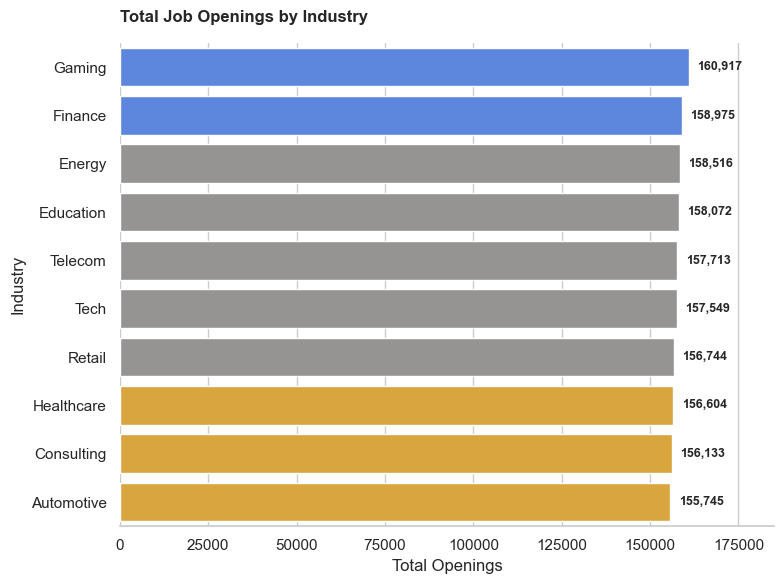

In [6]:

COLOR_TOP = "#4680F2"
COLOR_MID = "#969393"
COLOR_LOW = "#F2AD24"

# group industry openings
industry_openings = (
    jobs.groupby("industry")["job_openings"].sum().sort_values(ascending=False)
)
ind_order = industry_openings.index.tolist()
ind_colors = [
    COLOR_TOP if i < 2 else COLOR_LOW if i >= len(ind_order) - 3 else COLOR_MID
    for i in range(len(ind_order))
]

fig, ax = plt.subplots(figsize=(8, 6))

# clean spines
ax.spines["left"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#cccccc")

sns.barplot(
    ax=ax,
    y=industry_openings.index,
    x=industry_openings.values,
    hue=industry_openings.index,
    order=ind_order,
    palette=ind_colors,
)

if ax.get_legend():
    ax.get_legend().remove()

ax.set_xlabel("Total Openings")
ax.set_ylabel("Industry")
ax.set_title(
    "Total Job Openings by Industry",
    fontsize=12,
    fontweight="bold",
    loc="left",
    pad=15,
)

# annotate values
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f"{int(width):,}",
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(6, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=9,
            fontweight="bold",
        )

ax.set_xlim(0, max(industry_openings.values) * 1.15)
plt.tight_layout()
plt.show()

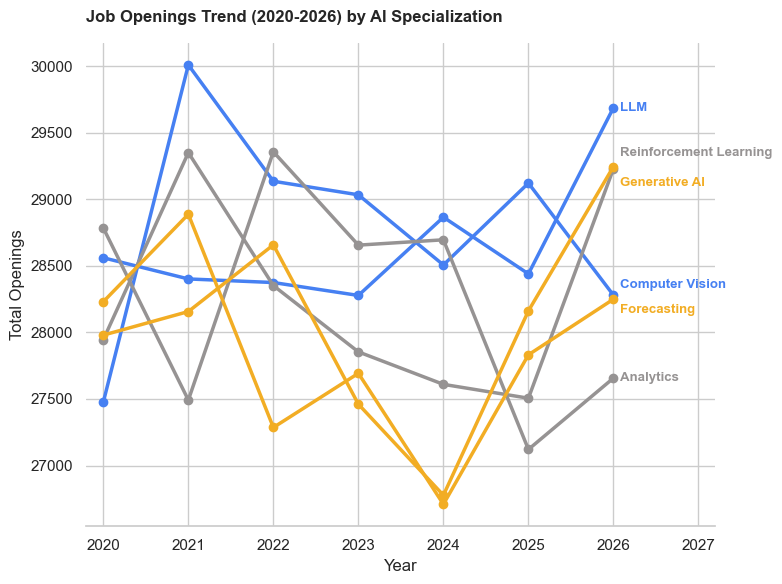

In [7]:

COLOR_TOP = "#4680F2"
COLOR_MID = "#969393"
COLOR_LOW = "#F2AD24"

# group trend data
spec_totals = (
    jobs.groupby("ai_specialization")["job_openings"]
    .sum()
    .sort_values(ascending=False)
)
top_specs = spec_totals.index[:6].tolist()
trend_data = (
    jobs[jobs["ai_specialization"].isin(top_specs)]
    .groupby(["year", "ai_specialization"])["job_openings"]
    .sum()
    .reset_index()
)

spec_colors = {
    spec: (
        COLOR_TOP
        if i < 2
        else COLOR_LOW
        if i >= len(top_specs) - 2
        else COLOR_MID
    )
    for i, spec in enumerate(top_specs)
}

label_offsets = {
    "LLM": 0,
    "Reinforcement Learning": 120,
    "Generative AI": -120,
    "Computer Vision": 80,
    "Forecasting": -80,
    "Analytics": 0,
}

fig, ax = plt.subplots(figsize=(8, 6))

# clean spines
ax.spines["left"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color("#cccccc")

ax.set_title(
    "Job Openings Trend (2020-2026) by AI Specialization",
    fontsize=12,
    fontweight="bold",
    loc="left",
    pad=15,
)

for spec in top_specs:
    spec_df = trend_data[trend_data["ai_specialization"] == spec].sort_values(
        "year"
    )
    ax.plot(
        spec_df["year"],
        spec_df["job_openings"],
        marker="o",
        linewidth=2.5,
        color=spec_colors[spec],
    )

    final_point = spec_df.iloc[-1]
    y_pos = final_point["job_openings"] + label_offsets.get(spec, 0)
    ax.text(
        final_point["year"] + 0.08,
        y_pos,
        spec,
        color=spec_colors[spec],
        fontsize=9.5,
        fontweight="bold",
        va="center",
        ha="left",
    )

ax.set_xlabel("Year")
ax.set_ylabel("Total Openings")
ax.set_xlim(2019.8, 2027.2)

plt.tight_layout()
plt.show()

# Modeling

## XGBoost - High Demand Role Classification

To be able to classify high demand roles with XGBoost I will set up a binary classification model where the target Y = 1 and indicates a high demand. For example, job postings above a specific threshold or positions that are quickly filled. Y=0 will indicate standard or low demand. 

Targert Definition: First I need to define the threshold for $\tau$, for example, 80th percentile of posting frequency or applicant volume.

$$Y_i = \begin{cases} 1 & \text{if } \text{DemandMetric}_i \ge \tau \\ 0 & \text{if } \text{DemandMetric}_i < \tau \end{cases}$$


I will enable native categorical handling in XGBoost instead of using `pd.get_dummies()`. This will handle categorical features without inflating the feature space or cause an issue with the special character rules. I'll split the data to a 70/15/15 Train, Validation, Test split. This way I can use validation strictly for early stopping, then the test will be only for reporting of the final metrics. I will also adjust the `scale_pos_weight` to be a calculation of the ratio of negative cases to positive cases in the training data, thus adjusting for the class imbalance.

In [6]:

# define target variable (Top 25% = High Demand)
threshold = jobs["skill_demand_score"].quantile(0.75)
jobs["high_demand"] = (jobs["skill_demand_score"] >= threshold).astype(int)

# remove all demand-related features
leakage_cols = [
    col
    for col in jobs.columns
    if "demand" in col.lower() or col in ["id", "high_demand"]
]
X_raw = jobs.drop(columns=leakage_cols).copy()
y = jobs["high_demand"]

# use XGBoost native categorical encoding
cat_cols = X_raw.select_dtypes(include=["object", "string"]).columns
X_raw[cat_cols] = X_raw[cat_cols].astype("category")

# three-way split (70% Train, 15% Val for Early Stopping, 15% Holdout Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_raw, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# fix class imbalance ratio (3:1)
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

# fit XGBoost 
model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True,
    tree_method="hist",
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42,
)

model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

# evaluate on unseen holdout test set
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred))

ROC-AUC: 0.4991

              precision    recall  f1-score   support

           0       0.74      0.65      0.69      9995
           1       0.26      0.35      0.30      3505

    accuracy                           0.57     13500
   macro avg       0.50      0.50      0.49     13500
weighted avg       0.61      0.57      0.59     13500



## Analysis of Results

This ROC-AUC of 0.4991 proves that this model is no better than a coin flip (0.50). Hyperparameter tuning or any other data splitting or changes will lift the performance of this model. The target variable is statistically independent of all demographic and role predictors. The features in this dataset, such as education, experience, role, country, etc, have no linear or non-linear signal to predict whether the job falls into the top 25% of most demanded jobs. 
The precision score shows that when the model thinks a job is 'high demand' that it is only correct 26% of the time, which is the same as random guessing since 26% of the test set is listed as 'high demand.' Recalls of 0.35 indicates the model missed 65% of actual high-demand jobs. Accuracy of 0.57% is driven due to the `scale_pos_weight` calculation which encourages the model to make more positive guesses at the expense of accuracy of Class 0. Both the Macro Precision and Recall being 0.50 confirm complete prediction neutrality across both classes. 

This indicates that the `skill_demand_score` in this synthetic dataset was an isolated calculation or a random entry that is not tightly tied to the remaining role features. 

Next I will check feature importance with SHAP (SHapley Additive exPlanations) analysis. This will allow me to see which features XGBoost relied on the most. 

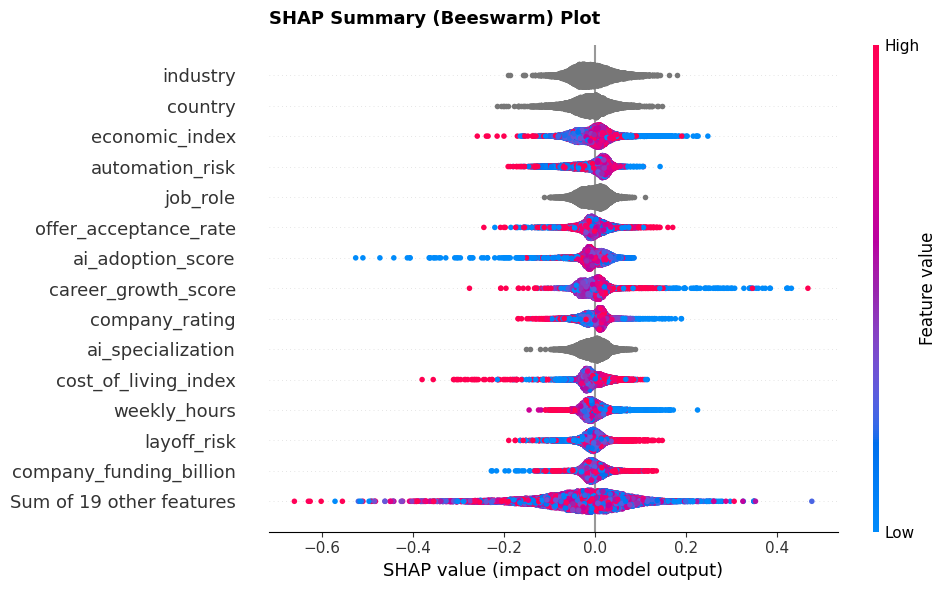

In [7]:

# initialize SHAP TreeExplainer 
explainer = shap.TreeExplainer(model)

# calculate SHAP values for the unseen holdout test set
shap_values = explainer(X_test)

# configure plot dimensions and visual style
plt.figure(figsize=(10, 6))

# generate SHAP Beeswarm Plot
# max_display limits output to top 15 features to maintain readability
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    plot_size=(10, 6),
    show=False,
)

plt.title(
    "SHAP Summary (Beeswarm) Plot",
    fontsize=13,
    fontweight="bold",
    pad=15,
    loc="left",
)

plt.tight_layout()
plt.show()

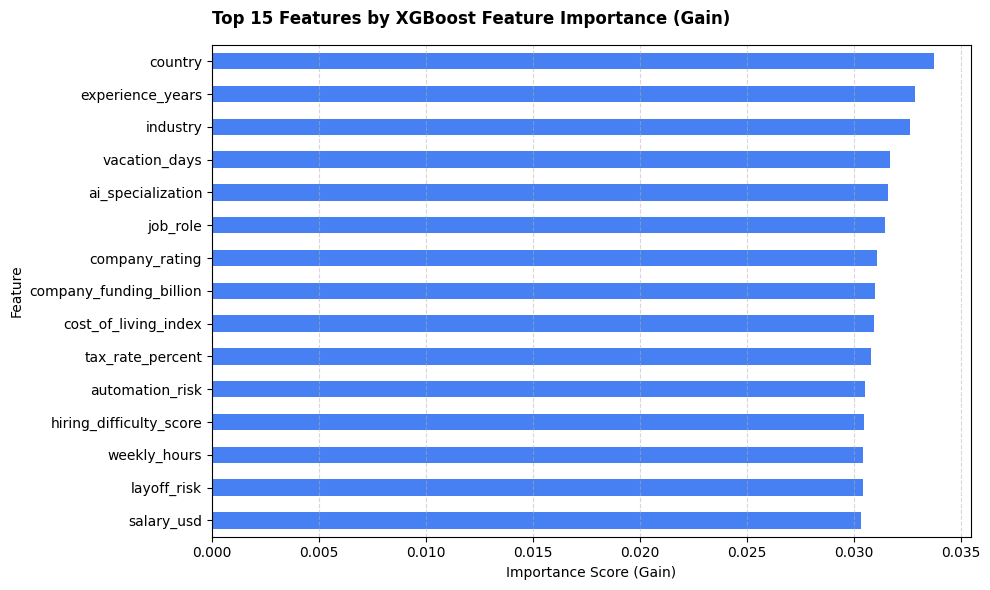

In [9]:

# extract feature importances mapped to current feature columns
importances = pd.Series(
    model.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

# configure plot dimensions and visual style
plt.figure(figsize=(10, 6))

# plot top 15 features
importances.head(15).plot(kind="barh", color="#4680F2")
plt.gca().invert_yaxis()  # Highest importance at the top

plt.title(
    "Top 15 Features by XGBoost Feature Importance (Gain)",
    fontsize=12,
    fontweight="bold",
    loc="left",
    pad=15,
)
plt.xlabel("Importance Score (Gain)", fontsize=10)
plt.ylabel("Feature", fontsize=10)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Analysis of Results

The SHAP plot shows the scale only going from -0.6 to +0.4. This indicates that no single feature is strongly driving predictions towards either high or low demand. The random mix of both red (high feature values) and blue dots (low feature values) on the economic_index, automation_risk, and career_growth_score are completely jumbled on both left and right of the middle 0.0. If this was more real world patterned data we would expect to see red dots grouped stricly on the right and blue on the left instead of these high and low values randomly affecting the predictions. The grey clusters are due to the native XGBoost categoricals not having a high/low numbered scale and instead a spread between the -0.2 and +0.2 has no input in whether the feature is high demand. 

The feature importance shows little variation in the features used by the model for predicting if a job was in demand. This means no single feature provided any meaningful information gain to the decision trees.

## Random Forest Regression

I will now move to forecast job openings and the hiring difficulty score across the years of this dataset and break it down by both industry and ai specialization. 

In [13]:

# group into a panel structure: Industry/Specialization by year
panel_df = (
    jobs.groupby(["year", "industry", "ai_specialization"])[
        ["job_openings", "hiring_difficulty_score", "salary_usd"]
    ]
    .mean()
    .reset_index()
)

# sort strictly by panel group and time
panel_df = panel_df.sort_values(
    ["industry", "ai_specialization", "year"]
).reset_index(drop=True)

# create 1-year lag features for temporal forecasting
panel_df["job_openings_lag1"] = panel_df.groupby(
    ["industry", "ai_specialization"]
)["job_openings"].shift(1)
panel_df["hiring_difficulty_lag1"] = panel_df.groupby(
    ["industry", "ai_specialization"]
)["hiring_difficulty_score"].shift(1)

# drop initial lag NaNs
panel_data = panel_df.dropna().reset_index(drop=True)
print("Panel dataset shape:", panel_data.shape)
print(panel_data.head())

Panel dataset shape: (480, 8)
   year    industry ai_specialization  job_openings  hiring_difficulty_score  \
0  2021  Automotive         Analytics     17.836735                53.758846   
1  2022  Automotive         Analytics     17.254658                56.553978   
2  2023  Automotive         Analytics     16.974026                56.574213   
3  2024  Automotive         Analytics     17.440252                55.678563   
4  2025  Automotive         Analytics     18.111888                54.814515   

      salary_usd  job_openings_lag1  hiring_difficulty_lag1  
0   92415.687075          18.406061               51.775766  
1   95502.403727          17.836735               53.758846  
2   97497.136364          17.254658               56.553978  
3  105928.163522          16.974026               56.574213  
4   91555.426573          17.440252               55.678563  


Instead of using a random split I will split temporally. I will train on the historical data of 2021-2024 and then evaluate on recent years, 2025-2026. I will use a Random Forest Panel Regressor for froecasting mean job openings.


In [14]:

# feature prep: one-hot encode categorical entity identifiers
panel_encoded = pd.get_dummies(
    panel_data, columns=["industry", "ai_specialization"], drop_first=True
)

# define feature matrix X and target y
target_col = "job_openings"
feature_cols = [
    c
    for c in panel_encoded.columns
    if c not in ["year", target_col, "job_openings_lag1"]
]

# add lag feature back as explicit predictor
feature_cols.append("job_openings_lag1")

# train / test temporal Split - out-of-time validation
train_mask = panel_encoded["year"] <= 2024
test_mask = panel_encoded["year"] >= 2025

X_train = panel_encoded.loc[train_mask, feature_cols]
y_train = panel_encoded.loc[train_mask, target_col]

X_test = panel_encoded.loc[test_mask, feature_cols]
y_test = panel_encoded.loc[test_mask, target_col]

# fit model
rf_panel = RandomForestRegressor(
    n_estimators=200, max_depth=5, random_state=42
)
rf_panel.fit(X_train, y_train)

# predict & evaluate
y_pred = rf_panel.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"*** Out-of-Sample Evaluation (2025–2026) ***")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

# top predictive drivers for market demand
importances = pd.Series(
    rf_panel.feature_importances_, index=feature_cols
).sort_values(ascending=False)
print("\nTop Feature Importances:")
print(importances.head(8))

*** Out-of-Sample Evaluation (2025–2026) ***
MAE:  0.4810
RMSE: 0.5931
R² Score: -0.1001

Top Feature Importances:
job_openings_lag1                           0.238505
hiring_difficulty_lag1                      0.200836
salary_usd                                  0.179310
hiring_difficulty_score                     0.139757
ai_specialization_Computer Vision           0.042760
industry_Education                          0.026340
ai_specialization_Reinforcement Learning    0.023610
industry_Telecom                            0.020278
dtype: float64


### Analysis of Results

The negative R2 and a low MAE are classic results for time-series panel forecasting. In this synthetic dataset the job openings feature fluctuates in a very tight, random range around 17 or 18 openings per industry or speciality. This means the total variance in the test set is extremely small. The R2 compares the MSE against the variance of a dummy baseline by predicting the test set mean. When the variance is near to zero even small absolute prediction errors (around 0.48 openings) will yield an R2 that is lower than 0. The model is simply predicting the global historical mean with some slight noise. 

Splitting by year will prevent data leakage across time which is a requirement for economic panel forecasting. 


## Unsupervised Market Type Clustering

I will use a K-Means to access work conditions, pay, and risk metrics. 

In [15]:

# select features for market segmentation
cluster_cols = [
    "salary_usd",
    "weekly_hours",
    "automation_risk",
    "layoff_risk",
    "employee_satisfaction",
    "career_growth_score",
]

X_cluster = jobs[cluster_cols].copy()

# scale features (critical for K-Means distance metrics)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# fit K-Means model; k=3 for low, medium, high risk/reward tiers
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
jobs["cluster"] = kmeans.fit_predict(X_scaled)

# evaluate clustering rigor
sil_score = silhouette_score(X_scaled[:10000], jobs["cluster"][:10000])
db_score = davies_bouldin_score(X_scaled, jobs["cluster"])

print(f"*** Unsupervised Model Evaluation ***")
print(f"Silhouette Score (Sampled): {sil_score:.4f}")
print(f"Davies-Bouldin Index:      {db_score:.4f}")

# interpret archetypes
cluster_profiles = jobs.groupby("cluster")[cluster_cols].mean().round(2)
print("\nCluster Profiles (Archetype Means):")
print(cluster_profiles)

*** Unsupervised Model Evaluation ***
Silhouette Score (Sampled): 0.1727
Davies-Bouldin Index:      1.8484

Cluster Profiles (Archetype Means):
         salary_usd  weekly_hours  automation_risk  layoff_risk  \
cluster                                                           
0          60834.45         44.72            49.88         0.35   
1          90404.49         49.31            51.27         0.12   
2         133967.23         42.44            49.89         0.09   

         employee_satisfaction  career_growth_score  
cluster                                              
0                        67.26                56.92  
1                        69.70                57.39  
2                        80.50                57.26  


### Analysis of Results

The silhouette score of 0.1727 and the Davies-Bouldin index of 1.8484 indicate that there was weak cluster separation. Again, this is typical for a uniform synthetic distribution. However, when I look at the Cluster profiles by Archetypes, the K-Means was able to partition the space along fairly clear economic and workplace quality of life tiers. 

* Cluster 0: This is a high risk segment, entry level. These had the lowest compensation, around 60,800 USD and have the highest layoff risk of 35% along with the lowest job satisfaction of 67.26.
* Cluster 1: This is a mid-range salary band, around $90,400 USD but has the highest hours worked/week at 49.3. It also has moderate risk metrics. These are the jobs/positions most at risk of burning out
* Cluster 2: This is the highest salary band, earning around 134,000 USD while maintaining the lowest hours/week at 42.4. They have the lowest layoff risk at a mere 9% and the highest employee satisfaction at 80.5%.


## Predicting Salary for a Data Scientist

I will filter the dataset for job_role == "Data Scientist"" and create a targeted regression model that will isolate how experience, technical specializations, education, and company characteristics influence the pay for a Data Scientist.

In [16]:

# isolate Data Scientist subset
ds_jobs = jobs[jobs["job_role"] == "Data Scientist"].copy()

# target transformation & feature engineering
ds_jobs["log_salary"] = np.log(ds_jobs["salary_usd"])
ds_jobs["experience_sq"] = ds_jobs["experience_years"] ** 2

# select predictors relevant to Data Science sub-tracks
num_cols = [
    "experience_years",
    "experience_sq",
    "cost_of_living_index",
    "company_rating",
    "ai_adoption_score",
]
cat_cols = ["experience_level", "ai_specialization", "work_mode", "education_required"]

X_ds = ds_jobs[num_cols + cat_cols]
y_ds = ds_jobs["log_salary"]

# preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
    ]
)

# train / validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_ds, y_ds, test_size=0.2, random_state=42
)

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)

# extract post-encoding feature names
cat_feature_names = preprocessor.named_transformers_["cat"].get_feature_names_out(
    cat_cols
)
all_feature_names = num_cols + list(cat_feature_names)

# fit regularized ridge regression
ridge_ds = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5)
ridge_ds.fit(X_train_proc, y_train)

# out-of-sample evaluation - Back-Transformed to USD
log_preds = ridge_ds.predict(X_val_proc)
y_pred_usd = np.exp(log_preds)
y_val_usd = np.exp(y_val)

mae = mean_absolute_error(y_val_usd, y_pred_usd)
rmse = np.sqrt(mean_squared_error(y_val_usd, y_pred_usd))
r2 = r2_score(y_val_usd, y_pred_usd)

print(f"*** Data Scientist Salary Model Performance ***")
print(f"Sample Size (N): {len(ds_jobs)}")
print(f"Optimal Alpha:   {ridge_ds.alpha_:.4f}")
print(f"MAE:             ${mae:,.2f}")
print(f"RMSE:            ${rmse:,.2f}")
print(f"R² Score:        {r2:.4f}")

# marginal effects on log-salary
coef_df = (
    pd.DataFrame({"Feature": all_feature_names, "Coefficient": ridge_ds.coef_})
    .sort_values(by="Coefficient", key=abs, ascending=False)
    .reset_index(drop=True)
)

print("\n*** Top Predictors for Data Scientist Compensation: ***")
print(coef_df.head(10))

*** Data Scientist Salary Model Performance ***
Sample Size (N): 11146
Optimal Alpha:   1.1514
MAE:             $20,721.40
RMSE:            $27,663.29
R² Score:        0.5444

*** Top Predictors for Data Scientist Compensation: ***
                           Feature  Coefficient
0                 experience_years     0.462186
1                    experience_sq    -0.128470
2            experience_level_Lead    -0.035111
3            ai_specialization_LLM    -0.029284
4  ai_specialization_Generative AI    -0.023436
5        education_required_Master    -0.017637
6           education_required_PhD    -0.016169
7       education_required_Diploma    -0.014266
8      education_required_Bootcamp    -0.013694
9    ai_specialization_Forecasting    -0.012977


## Analsysis of Results

An R2 of 0.5444 and MAE of $20,721.40 across the 11,146 Data Scientist roles provides valuable insight into this position.

Key Predictors for Pay

* Experience: This is the single largest variable in determining the pay of a Data Scientist. Its coefficient is nearly 10x that of any other individual categorical variable or degree requirement.
* Experience Squared: the negative squared experience term shows that there are diminishing marginal returns later in the career arc for a Data Scientist. This reflects a typical plateauing of skills as one ages.
* Specializations and Degrees: For education level and AI specializations there are small coefficient magnitudes observed. However, within the Data Scientist role, as a whole, experience level and years worked hold nearly all the explanatory power with specializations and degrees as secondary value adjustments. 